# CartPole: adapting the lesson to Gymnasium

Use the maintained Gymnasium API: `reset()` returns observation/info and
`step()` distinguishes environment termination from a time limit.
`CartPole-v1` is capped at **200 steps** to reproduce the lesson's task.
The lesson criterion is mean return at least 195 over 100 episodes. That
differs from the longer default horizon and official criterion of v1.

In [1]:
import os
os.environ['PYGAME_HIDE_SUPPORT_PROMPT']='1'
os.environ['SDL_VIDEODRIVER']='dummy'
import sys
sys.path.insert(0,'..')
import warnings
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image
from IPython.display import display
import gymnasium as gym
from qlearning import discretize,train_gym,evaluate_gym

In [2]:
environment='CartPole-v1'
bounds=((-2.4,2.4),(-3,3),(-0.2095,0.2095),(-3.5,3.5))
bins=(3,3,8,12)
env=gym.make(environment,max_episode_steps=200)
observation,info=env.reset(seed=42)
print('Actions:',env.action_space,'Observations:',env.observation_space)
print('Continuous observation:',observation,'Discretized:',discretize(observation,bounds,bins))
env.close()
random_results=pd.DataFrame(evaluate_gym(environment,None,bounds,bins,range(200000,200100),policy='random'))
print('Random-policy mean return:',random_results['return'].mean())

Actions: Discrete(2) Observations: Box([-4.8               -inf -0.41887903        -inf], [4.8               inf 0.41887903        inf], (4,), float32)
Continuous observation: [ 0.0273956  -0.00611216  0.03585979  0.0197368 ] Discretized: (1, 1, 4, 6)
Random-policy mean return: 24.35


## Training and checkpoint selection

Adapt the original Bellman update with clipped bins, alpha 0.15 and gamma
0.99. Epsilon is the probability of exploration, decreasing from 1 to 0.02.
Every 1,000 episodes, select an independent **copy** of the best Q table
using 25 validation seeds in 100000–100024. Training seeds and the final
100 test seeds are disjoint. Neither success shaping nor a hand-coded
balancing controller is used.

In [3]:
q_final,q_best,returns,checkpoints=train_gym(environment,bounds,bins,6000,42,0.15,0.99,1000)
assert not np.shares_memory(q_final,q_best)
pd.DataFrame(checkpoints).to_csv('cartpole-validation.csv',index=False)
np.savez_compressed('cartpole-policy.npz',final=q_final,best=q_best,returns=returns)

CartPole-v1 {'episode': 1000, 'validation_return': 160.28, 'training_mean_100': 36.61}


CartPole-v1 {'episode': 2000, 'validation_return': 154.32, 'training_mean_100': 58.96}


CartPole-v1 {'episode': 3000, 'validation_return': 94.64, 'training_mean_100': 91.96}


CartPole-v1 {'episode': 4000, 'validation_return': 128.88, 'training_mean_100': 130.81}


CartPole-v1 {'episode': 5000, 'validation_return': 200.0, 'training_mean_100': 200.0}


CartPole-v1 {'episode': 6000, 'validation_return': 200.0, 'training_mean_100': 192.46}


,mean_return,min_steps,reached_200
policy,,,
Best greedy,200.00,200,100
Best sampled,200.00,200,100
Final greedy,200.00,200,100
Random,24.35,9,0


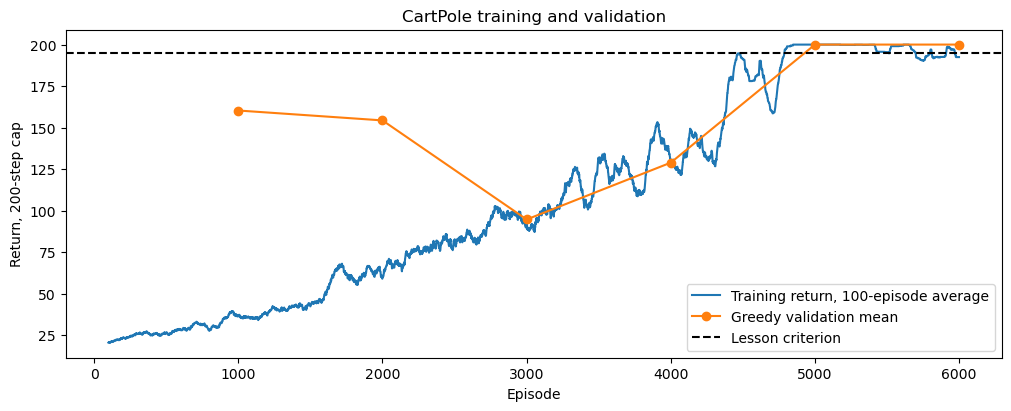

In [4]:
results=[]
for name,table,policy in [('Random',q_best,'random'),('Final greedy',q_final,'greedy'),
                          ('Best greedy',q_best,'greedy'),('Best sampled',q_best,'sampled')]:
    frame=pd.DataFrame(evaluate_gym(environment,table,bounds,bins,range(200000,200100),policy))
    frame['policy']=name
    results.append(frame)
results=pd.concat(results,ignore_index=True)
summary=results.groupby('policy').agg(mean_return=('return','mean'),min_steps=('steps','min'),
                                      reached_200=('steps',lambda value:int(value.eq(200).sum())))
display(summary)
assert summary.loc['Best greedy','mean_return']>=195
results.to_csv('cartpole-test-episodes.csv',index=False)
summary.to_csv('cartpole-results.csv')
fig,ax=plt.subplots(figsize=(10,4),layout='constrained')
pd.Series(returns).rolling(100,min_periods=100).mean().plot(ax=ax,label='Training return, 100-episode average')
validation=pd.DataFrame(checkpoints)
ax.plot(validation.episode,validation.validation_return,marker='o',label='Greedy validation mean')
ax.axhline(195,color='black',linestyle='--',label='Lesson criterion')
ax.set(xlabel='Episode',ylabel='Return, 200-step cap',title='CartPole training and validation')
ax.legend()
fig.savefig('cartpole-training.png',dpi=150)
plt.show()

In [5]:
with warnings.catch_warnings():
    warnings.filterwarnings('ignore',message='pkg_resources is deprecated as an API.*',category=UserWarning)
    env=gym.make(environment,max_episode_steps=200,render_mode='rgb_array')
    observation,_=env.reset(seed=200000)
    frames=[]
    for count in range(200):
        if count%4==0: frames.append(Image.fromarray(env.render()))
        action=int(np.argmax(q_best[discretize(observation,bounds,bins)]))
        observation,reward,terminated,truncated,_=env.step(action)
        if terminated or truncated: break
    env.close()
frames[0].save('cartpole.gif',save_all=True,append_images=frames[1:],duration=80,loop=0)
print('Rendered demonstration steps:',count+1)

Rendered demonstration steps: 200


## Challenge answers

The table directly compares final versus validation-selected checkpoints,
and probability sampling versus greedy argmax on identical final test seeds.
Best and final arrays are separate copies; assigning the same mutable array
to `Qbest` would not preserve an earlier policy. A 100-episode training
average can be distorted by exploration, so the lesson success claim uses
100 consecutive, exploration-free test episodes instead.

Bounds on cart and angular velocities are explicit discretization choices,
not physical limits imposed by the environment. Out-of-range observations
clip to edge bins. A time limit stops an episode, while only true terminal
states suppress the Bellman bootstrap, following Gymnasium's distinction.
The [Mountain Car assignment](assignment.ipynb) reuses the same learner.